# 05 · Análisis exploratorio, insights y conclusiones

**Análisis**

Se parte del dataset con las variables derivadas en la etapa 4 (1.006 ofertas, 27 columnas) para responder dónde están las oportunidades laborales para estudiantes y recién egresados: cuánta oferta de entrada hay, dónde está y cuánto paga. Se trabaja con medianas y no con promedios, porque la cola de sueldos altos desplaza el promedio.

**Resultado de este análisis:** el 42,4 % de las ofertas es de nivel inicial, con una mediana de S/ 3.775 frente a S/ 5.670 del resto. La segmentación con K-means separa cuatro perfiles y muestra que el tamaño de la entidad define a qué cargo se entra: la puerta de entrada paga S/ 5.500 en entidades grandes y S/ 2.500 en pequeñas. Lima-Callao paga un 86 % más que el resto del país. Se generaron 12 figuras en `reports/figures/`, cada una con su interpretación.

Los datos corresponden a las ofertas vigentes en el portal el 18 de septiembre de 2026, publicadas el 17 y 18 de ese mes. El nivel del puesto y el área funcional se infieren de la denominación del cargo, ya que el portal no publica la experiencia ni la formación exigidas.

## Preparación

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Rutas: usa src/config.py cuando el notebook corre dentro del repositorio; si no (por ejemplo
# en Colab, con solo el CSV subido), trabaja sobre la carpeta actual.
RAIZ = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists()), None)

if RAIZ is not None:
    sys.path.insert(0, str(RAIZ))
    from src import config
    from src.graficos import guardar_figura
    ENCODING = config.ENCODING
    DIR_FIGURAS = config.DIR_FIGURAS
    CANDIDATOS = [config.ARCHIVO_FINAL,
                  config.DIR_PROCESSED / "talento_peru_features.csv",
                  config.DIR_INTERIM / "talento_peru_features.csv"]
else:
    ENCODING = "utf-8"
    DIR_FIGURAS = Path("reports/figures")
    CANDIDATOS = [Path("talento_peru_features.csv"), Path("data/processed/talento_peru_features.csv")]

    def guardar_figura(nombre, fig=None, dpi=200):
        DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
        (fig or plt.gcf()).savefig(DIR_FIGURAS / f"{nombre}.png", dpi=dpi, bbox_inches="tight")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
AZUL, VERDE, NARANJA, ROJO = "#4C72B0", "#55A868", "#DD8452", "#C44E52"

In [ ]:
ruta = next((r for r in CANDIDATOS if r.exists()), None)
if ruta is None:
    raise FileNotFoundError("Falta talento_peru_features.csv (salida de la etapa 4).")

df = pd.read_csv(ruta, encoding=ENCODING)
print(f"{len(df)} ofertas · {df.shape[1]} columnas · {df['vacantes'].sum()} vacantes")
assert df["id_oferta_hash"].is_unique, "Hay identificadores repetidos"
df.head(3)

1006 ofertas · 27 columnas · 1758 vacantes


,id_oferta_hash,puesto,entidad,numero_convocatoria,vacantes,remuneracion_pen,fecha_inicio_publicacion,fecha_fin_publicacion,departamento,distrito,...,area_funcional,nivel_puesto,es_nivel_inicial,tipo_entidad,macrorregion,masa_salarial_mensual,remuneracion_relativa,nivel_puesto_NA,rango_salarial_cod,ofertas_por_entidad
0,1af30dbb2f0f39e7d0c908cf,ESPECIALISTA LEGAL,PODER JUDICIAL,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORI...,1,5670.0,2026-09-18,2026-10-01,JUNIN,EL TAMBO,...,LEGAL Y JUDICIAL,NaN,0,JUSTICIA Y MINISTERIO PUBLICO,CENTRO,5670.0,0.872308,1,3,49
1,febb4d4b3da59b587a74d154,ASISTENTE LEGAL,PODER JUDICIAL,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORI...,1,4000.0,2026-09-18,2026-10-01,JUNIN,EL TAMBO,...,LEGAL Y JUDICIAL,NaN,1,JUSTICIA Y MINISTERIO PUBLICO,CENTRO,4000.0,1.297690,1,3,49
2,dcde0256d3fc65eed01f4f18,ASISTENTE ADMINISTRATIVO I MODULO,PODER JUDICIAL,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORI...,1,3470.0,2026-09-18,2026-10-01,JUNIN,EL TAMBO,...,ADMINISTRACION Y GESTION,1.0,1,JUSTICIA Y MINISTERIO PUBLICO,CENTRO,3470.0,1.125746,0,2,49


## 1. Exploración univariada

Antes de cruzar variables se describe cada una por separado: cómo se reparte el pago, cuánta oferta es de
nivel inicial, en qué áreas se concentra y en qué territorios.

### 1.1 Remuneración mensual

count     1006.0
mean      5150.0
50%       5364.0
min       1127.0
max      21000.0
Rango intercuartílico: S/ 3,103 a S/ 6,500


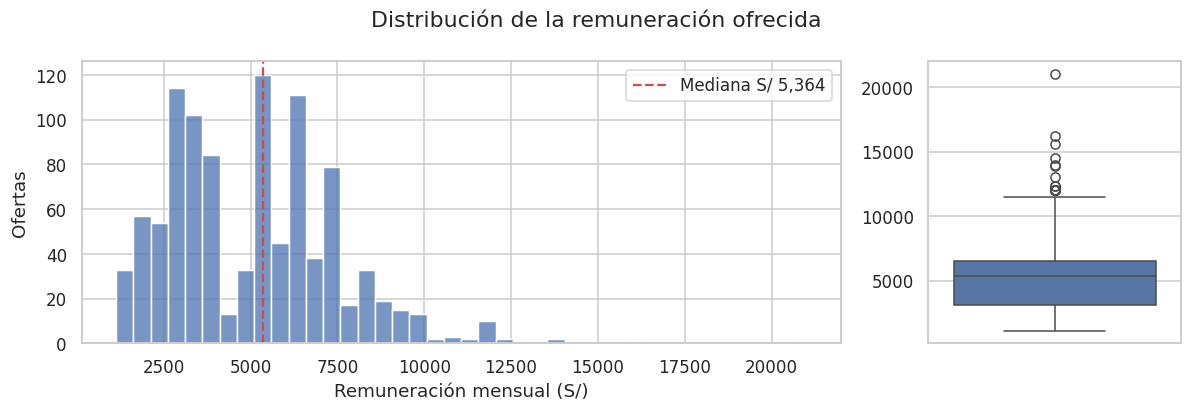

In [ ]:
resumen = df["remuneracion_pen"].describe()[["count", "mean", "50%", "min", "max"]]
q1, q3 = df["remuneracion_pen"].quantile([0.25, 0.75])
print(resumen.round(0).to_string())
print(f"Rango intercuartílico: S/ {q1:,.0f} a S/ {q3:,.0f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [3, 1]})
sns.histplot(df["remuneracion_pen"], bins=40, color=AZUL, ax=ax1)
ax1.axvline(df["remuneracion_pen"].median(), color=ROJO, linestyle="--",
            label=f"Mediana S/ {df['remuneracion_pen'].median():,.0f}")
ax1.set_xlabel("Remuneración mensual (S/)")
ax1.set_ylabel("Ofertas")
ax1.legend()
sns.boxplot(y=df["remuneracion_pen"], color=AZUL, ax=ax2)
ax2.set_ylabel("")
fig.suptitle("Distribución de la remuneración ofrecida")
plt.tight_layout()
guardar_figura("05_distribucion_remuneracion")
plt.show()

**Interpretación.** La mediana es S/ 5.364 y la mitad de las ofertas está entre S/ 3.103 y S/ 6.500. La
cola hasta S/ 21.000 empuja el promedio a S/ 5.150, por lo que todo el análisis usa medianas. Los escalones
del histograma son las escalas salariales del Estado (S/ 5.500, 6.500, 7.500).

### 1.2 ¿Cuánta oferta es de nivel inicial?

In [ ]:
n_ini = int(df["es_nivel_inicial"].sum())
print(f"Ofertas de nivel inicial: {n_ini} de {len(df)} ({n_ini / len(df):.1%})")
print(f"Vacantes de nivel inicial: {df.loc[df['es_nivel_inicial'] == 1, 'vacantes'].sum()} "
      f"de {df['vacantes'].sum()}")

comparacion = (df.assign(nivel=np.where(df["es_nivel_inicial"] == 1, "Nivel inicial", "Resto"))
                 .groupby("nivel")["remuneracion_pen"]
                 .agg(ofertas="size", mediana="median", q1=lambda s: s.quantile(.25),
                      q3=lambda s: s.quantile(.75), maximo="max"))
comparacion.round(0)

Ofertas de nivel inicial: 427 de 1006 (42.4%)
Vacantes de nivel inicial: 956 de 1758


,ofertas,mediana,q1,q3,maximo
nivel,,,,,
Nivel inicial,427,3775.0,2572.0,5500.0,14500.0
Resto,579,5670.0,3500.0,6620.0,21000.0


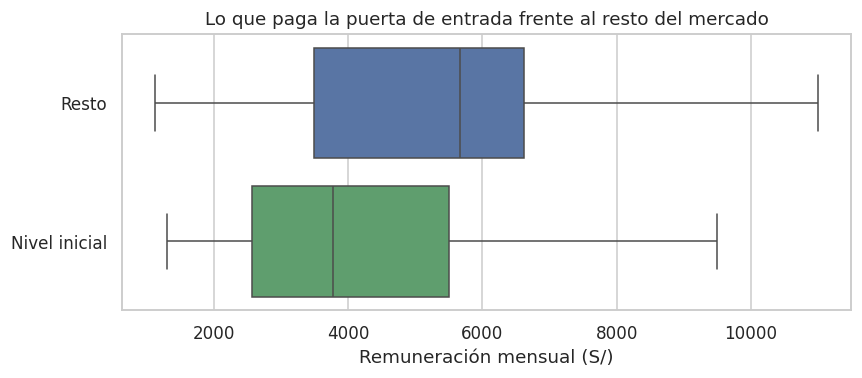

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.boxplot(data=df.assign(nivel=np.where(df["es_nivel_inicial"] == 1, "Nivel inicial", "Resto")),
            x="remuneracion_pen", y="nivel", hue="nivel", legend=False,
            palette={"Nivel inicial": VERDE, "Resto": AZUL}, showfliers=False, ax=ax)
ax.set_xlabel("Remuneración mensual (S/)")
ax.set_ylabel("")
ax.set_title("Lo que paga la puerta de entrada frente al resto del mercado")
plt.tight_layout()
guardar_figura("05_nivel_inicial_vs_resto")
plt.show()

**Interpretación.** El 42,4 % de las ofertas (427) es de nivel inicial, más de lo que haría suponer la
idea de que el Estado solo contrata perfiles con trayectoria. La contrapartida es el pago: S/ 3.775 de
mediana frente a S/ 5.670 del resto, un 33 % menos. Los dos bloques se superponen, así que hay ofertas de
entrada que pagan como las de perfiles con experiencia; encontrarlas es el objetivo de lo que sigue.

### 1.3 Áreas funcionales y territorio

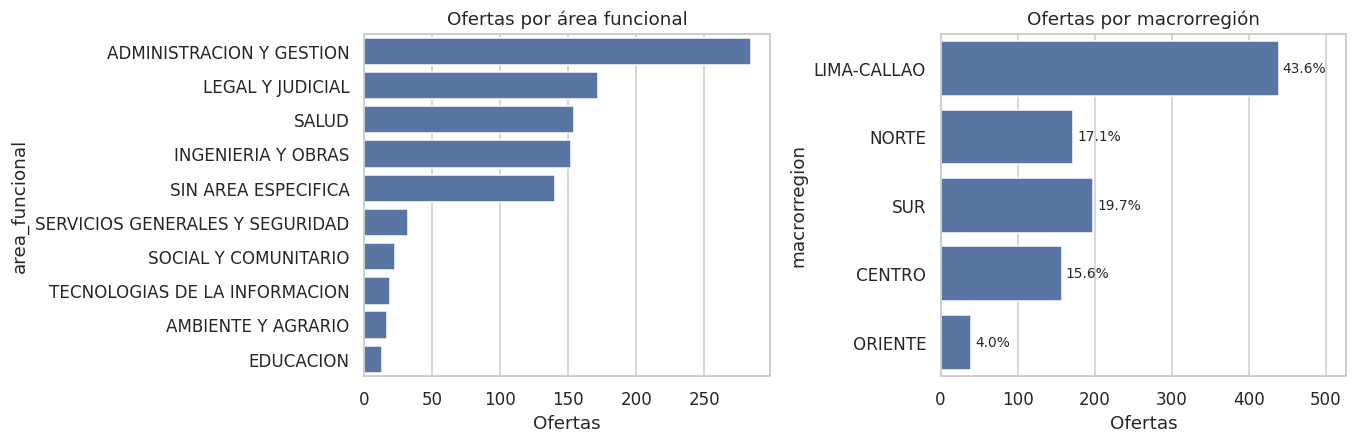

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.2))

areas = df["area_funcional"].value_counts()
sns.barplot(x=areas.values, y=areas.index, color=AZUL, ax=ax1)
ax1.set_xlabel("Ofertas")
ax1.set_title("Ofertas por área funcional")

ORDEN_MACRO = ["LIMA-CALLAO", "NORTE", "SUR", "CENTRO", "ORIENTE"]
macro = df["macrorregion"].value_counts().reindex(ORDEN_MACRO)
sns.barplot(x=macro.values, y=macro.index, color=AZUL, ax=ax2)
for i, v in enumerate(macro.values):
    ax2.text(v + 5, i, f"{v / len(df):.1%}", va="center", fontsize=9)
ax2.set_xlabel("Ofertas")
ax2.set_xlim(0, macro.max() * 1.2)
ax2.set_title("Ofertas por macrorregión")

plt.tight_layout()
guardar_figura("05_areas_y_territorio")
plt.show()

**Interpretación.** Administración (284 ofertas), legal (172), salud (154) e ingeniería (152) reúnen más
de la mitad del mercado; educación (13) y tecnologías de la información (19) son marginales en esta fuente.
Lima-Callao concentra el 43,6 % de las ofertas. Oriente, con 40, es muy pequeña para leer sus porcentajes
como representativos, y así se trata en adelante.

## 2. Relaciones entre variables

La pregunta ahora es dónde conviene buscar: qué áreas, qué entidades y qué territorios combinan una puerta
de entrada ancha con una remuneración aceptable.

### 2.1 Oportunidad por área: cuánta entrada hay y cuánto paga

In [ ]:
area = (df.groupby("area_funcional")
          .agg(ofertas=("id_oferta_hash", "size"),
               pct_inicial=("es_nivel_inicial", "mean"),
               mediana_general=("remuneracion_pen", "median")))
area["mediana_inicial"] = (df[df["es_nivel_inicial"] == 1]
                           .groupby("area_funcional")["remuneracion_pen"].median())
area["pct_inicial"] = (area["pct_inicial"] * 100).round(1)
area = area.sort_values("ofertas", ascending=False)
area[["mediana_general", "mediana_inicial"]] = area[["mediana_general", "mediana_inicial"]].round(0)
area

,ofertas,pct_inicial,mediana_general,mediana_inicial
area_funcional,,,,
ADMINISTRACION Y GESTION,284,49.6,4100.0,3400.0
LEGAL Y JUDICIAL,172,41.9,5670.0,5500.0
SALUD,154,33.1,4364.0,2797.0
INGENIERIA Y OBRAS,152,40.8,6500.0,5500.0
SIN AREA ESPECIFICA,140,35.7,4050.0,3490.0
SERVICIOS GENERALES Y SEGURIDAD,32,100.0,2350.0,2350.0
SOCIAL Y COMUNITARIO,23,30.4,4000.0,2804.0
TECNOLOGIAS DE LA INFORMACION,19,26.3,6500.0,4710.0
AMBIENTE Y AGRARIO,17,35.3,5000.0,7500.0


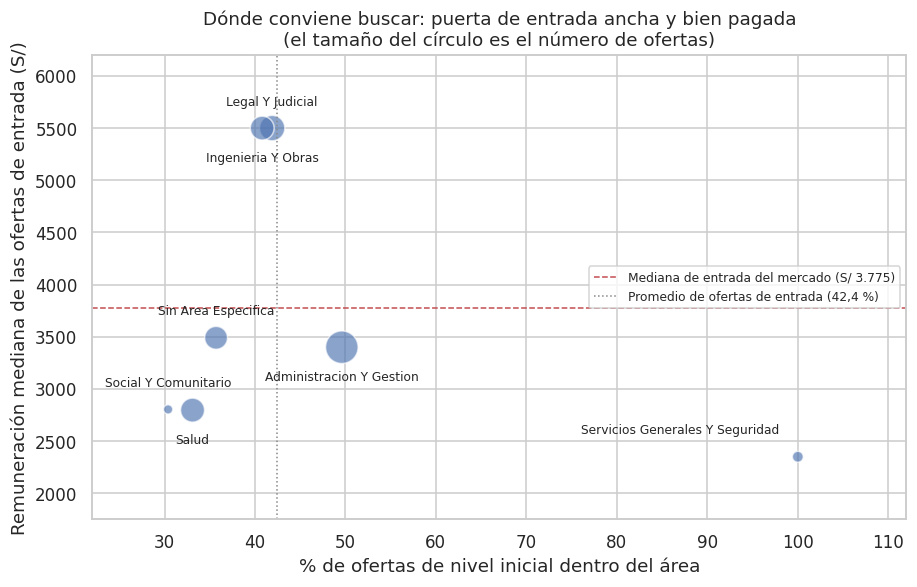

In [ ]:
grandes = area[area["ofertas"] >= 20]

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(grandes["pct_inicial"], grandes["mediana_inicial"],
           s=grandes["ofertas"] * 1.6, color=AZUL, alpha=0.65, edgecolor="white")
# Etiquetas alternando arriba/abajo para que no se superpongan
orden = grandes.sort_values("pct_inicial")
for i, (nombre, fila) in enumerate(orden.iterrows()):
    dy = 15 if i % 2 == 0 else -22
    ha = "right" if fila["pct_inicial"] > 90 else "center"
    dx = -12 if ha == "right" else 0
    ax.annotate(nombre.title(), (fila["pct_inicial"], fila["mediana_inicial"]),
                textcoords="offset points", xytext=(dx, dy), ha=ha, fontsize=8)
ax.axhline(df.loc[df["es_nivel_inicial"] == 1, "remuneracion_pen"].median(),
           color=ROJO, linestyle="--", linewidth=1,
           label="Mediana de entrada del mercado (S/ 3.775)")
ax.axvline(df["es_nivel_inicial"].mean() * 100, color="#888", linestyle=":", linewidth=1,
           label="Promedio de ofertas de entrada (42,4 %)")
ax.set_xlabel("% de ofertas de nivel inicial dentro del área")
ax.set_ylabel("Remuneración mediana de las ofertas de entrada (S/)")
ax.set_title("Dónde conviene buscar: puerta de entrada ancha y bien pagada\n(el tamaño del círculo es el número de ofertas)")
ax.set_xlim(22, 112)
ax.set_ylim(grandes["mediana_inicial"].min() - 600, grandes["mediana_inicial"].max() + 700)
ax.legend(loc="center right", fontsize=8)
plt.tight_layout()
guardar_figura("05_oportunidad_por_area")
plt.show()

**Interpretación.** El cuadrante útil es el superior derecho: mucha oferta de entrada y buen pago.

- **Legal y judicial** e **ingeniería y obras** son la mejor combinación: ~41 % de entrada y S/ 5.500 de
  mediana, muy por encima de los S/ 3.775 del mercado.
- **Administración y gestión** tiene la puerta más ancha en volumen (284 ofertas, 49,6 %), pero paga
  S/ 3.400: más probabilidad, menos sueldo.
- **Salud** engaña: su mediana general es S/ 4.364, pero la de entrada cae a S/ 2.797, porque las plazas
  bien pagadas exigen título y colegiatura.
- **Servicios generales** llega al 100 % de entrada solo porque sus cargos son auxiliares por definición.
  **Educación** y **TI** casi no ofrecen entrada (7,7 % y 26,3 %).

### 2.2 Quién contrata y cuánto paga

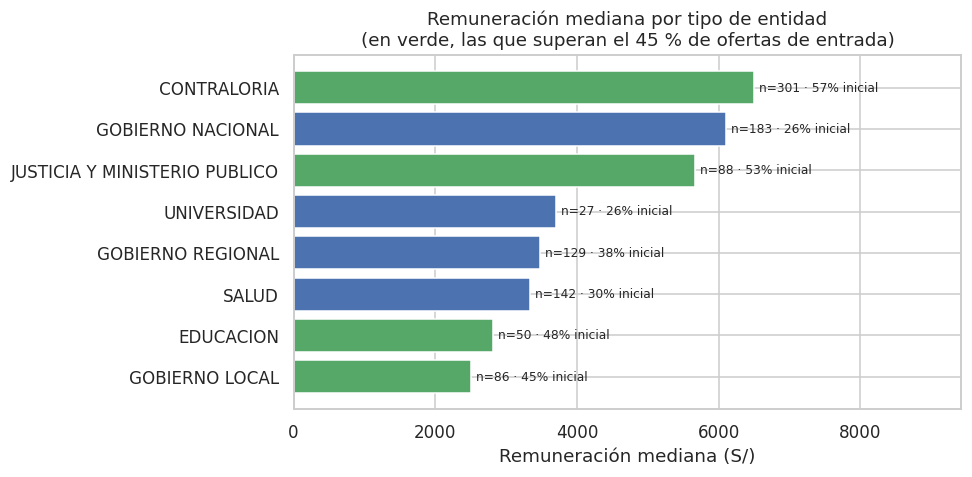

,ofertas,mediana,pct_inicial
tipo_entidad,,,
GOBIERNO LOCAL,86,2500.00,45.3
EDUCACION,50,2816.50,48.0
SALUD,142,3335.81,30.3
GOBIERNO REGIONAL,129,3479.00,38.0
UNIVERSIDAD,27,3700.00,25.9
JUSTICIA Y MINISTERIO PUBLICO,88,5670.00,53.4
GOBIERNO NACIONAL,183,6100.00,25.7
CONTRALORIA,301,6500.00,56.8


In [ ]:
entidad = (df.groupby("tipo_entidad")
             .agg(ofertas=("id_oferta_hash", "size"),
                  mediana=("remuneracion_pen", "median"),
                  pct_inicial=("es_nivel_inicial", "mean"))
             .sort_values("mediana"))
entidad["pct_inicial"] = (entidad["pct_inicial"] * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 4.5))
colores = [VERDE if p >= 45 else AZUL for p in entidad["pct_inicial"]]
ax.barh(entidad.index, entidad["mediana"], color=colores)
for i, (m, n, p) in enumerate(zip(entidad["mediana"], entidad["ofertas"], entidad["pct_inicial"])):
    ax.text(m + 70, i, f"n={n} · {p:.0f}% inicial", va="center", fontsize=8)
ax.set_xlabel("Remuneración mediana (S/)")
ax.set_xlim(0, entidad["mediana"].max() * 1.45)
ax.set_title("Remuneración mediana por tipo de entidad\n(en verde, las que superan el 45 % de ofertas de entrada)")
plt.tight_layout()
guardar_figura("05_remuneracion_por_tipo_entidad")
plt.show()
entidad

**Interpretación.** El tipo de entidad separa el mercado con más fuerza que el área: de S/ 2.500 en
gobiernos locales a S/ 6.500 en la Contraloría. Lo interesante son las barras verdes: **la Contraloría y el
sistema de justicia pagan por encima de la mediana y, a la vez, son los que más ofertas de entrada
publican** (56,8 % y 53,4 %), al revés de lo que haría suponer el sentido común.

### 2.3 El efecto de la concentración: Lima y la Contraloría

In [ ]:
sin_contraloria = df[df["tipo_entidad"] != "CONTRALORIA"]

print(f"La Contraloría publica {(df['tipo_entidad'] == 'CONTRALORIA').sum()} ofertas "
      f"({(df['tipo_entidad'] == 'CONTRALORIA').mean():.1%} del total) y "
      f"{(df.loc[df['tipo_entidad'] == 'CONTRALORIA', 'macrorregion'] == 'LIMA-CALLAO').mean():.0%} de ellas están en Lima-Callao.\n")

comparacion = pd.DataFrame({
    "Dataset completo": [df[df["macrorregion"] == "LIMA-CALLAO"]["remuneracion_pen"].median(),
                         df[df["macrorregion"] != "LIMA-CALLAO"]["remuneracion_pen"].median()],
    "Sin Contraloría": [sin_contraloria[sin_contraloria["macrorregion"] == "LIMA-CALLAO"]["remuneracion_pen"].median(),
                        sin_contraloria[sin_contraloria["macrorregion"] != "LIMA-CALLAO"]["remuneracion_pen"].median()],
}, index=["Lima-Callao", "Resto del país"])
comparacion.loc["Lima paga más (%)"] = (
    (comparacion.loc["Lima-Callao"] / comparacion.loc["Resto del país"] - 1) * 100
).round(1)
comparacion.round(0)

La Contraloría publica 301 ofertas (29.9% del total) y 63% de ellas están en Lima-Callao.



,Dataset completo,Sin Contraloría
Lima-Callao,6500.0,6000.0
Resto del país,3500.0,3374.0
Lima paga más (%),86.0,78.0


**Interpretación.** La Contraloría publica el 29,9 % de las ofertas y el 63 % de ellas están en Lima, así
que podría estar inventando la brecha territorial. Al repetir el cálculo sin esa entidad, la brecha baja de
86 % a 78 % pero no desaparece: el centralismo salarial no es artefacto de una entidad dominante.

### 2.4 Composición salarial de cada macrorregión

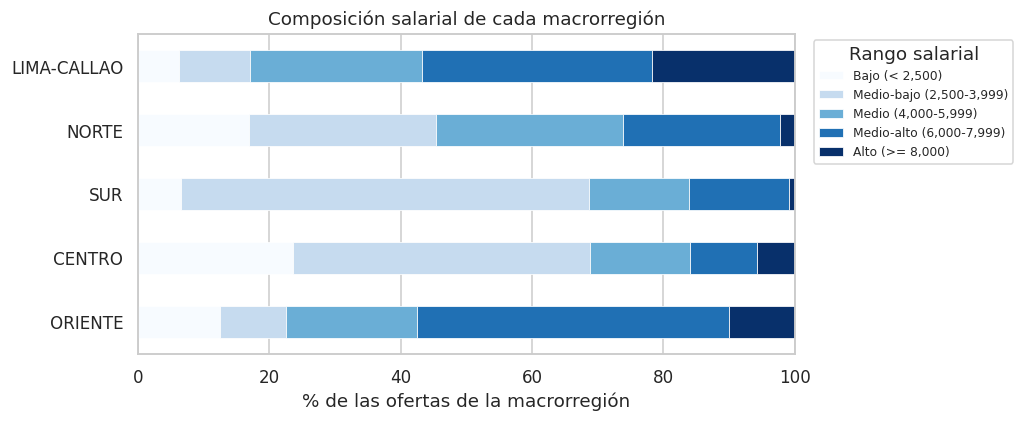

rango_salarial,"Bajo (< 2,500)","Medio-bajo (2,500-3,999)","Medio (4,000-5,999)","Medio-alto (6,000-7,999)","Alto (>= 8,000)"
macrorregion,,,,,
ORIENTE,12.5,10.0,20.0,47.5,10.0
CENTRO,23.6,45.2,15.3,10.2,5.7
SUR,6.6,62.1,15.2,15.2,1.0
NORTE,16.9,28.5,28.5,23.8,2.3
LIMA-CALLAO,6.2,10.9,26.2,34.9,21.9


In [ ]:
ORDEN_RANGOS = ["Bajo (< 2,500)", "Medio-bajo (2,500-3,999)", "Medio (4,000-5,999)",
                "Medio-alto (6,000-7,999)", "Alto (>= 8,000)"]
ORDEN_MACRO = ["ORIENTE", "CENTRO", "SUR", "NORTE", "LIMA-CALLAO"]

composicion = (df.groupby(["macrorregion", "rango_salarial"], observed=True).size()
                 .unstack()
                 .reindex(index=ORDEN_MACRO, columns=ORDEN_RANGOS))
composicion_pct = (composicion.div(composicion.sum(axis=1), axis=0) * 100).round(1)

ax = composicion_pct.plot.barh(stacked=True, figsize=(9.5, 4), colormap="Blues",
                               edgecolor="white", linewidth=0.5)
ax.set_xlabel("% de las ofertas de la macrorregión")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_title("Composición salarial de cada macrorregión")
ax.legend(title="Rango salarial", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
guardar_figura("05_composicion_salarial_macrorregion")
plt.show()
composicion_pct

**Interpretación.** La diferencia entre territorios no es solo de nivel, sino de **composición**: en
Lima-Callao los tramos medio-alto y alto suman más de la mitad de las ofertas, mientras que en el Sur el
62 % cae en el tramo medio-bajo. Fuera de Lima casi no se publican convocatorias en los tramos altos.

## 3. Segmentación de las ofertas

Hasta aquí se compararon variables de a dos. La segmentación busca si las ofertas forman **perfiles**
reconocibles al mirar varias características a la vez. Se usa K-means sobre cinco variables numéricas que
describen la oferta (no el territorio, para que los grupos no sean simplemente regiones), normalizadas con
`MinMaxScaler` para que todas pesen igual.

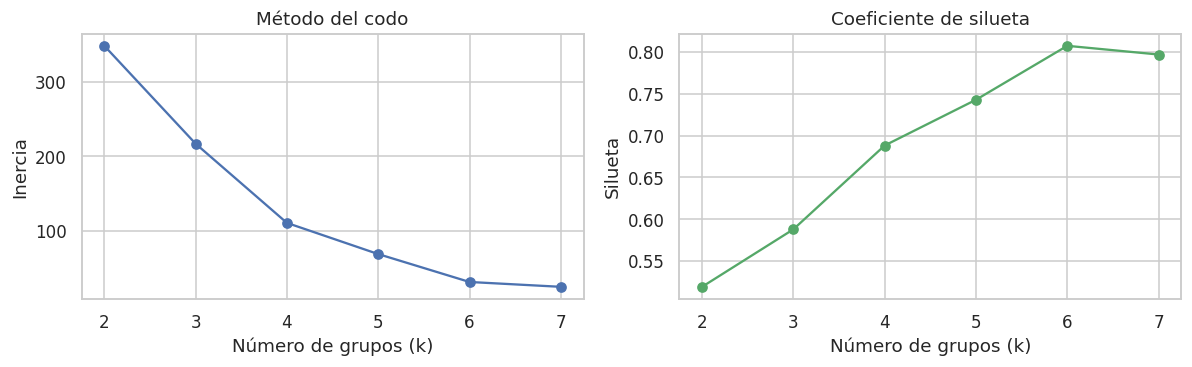

In [ ]:
VARIABLES = ["remuneracion_pen", "vacantes_log", "es_nivel_inicial",
             "ofertas_por_entidad", "nivel_puesto_NA"]
X = MinMaxScaler().fit_transform(df[VARIABLES])

inercia, siluetas, ks = [], [], range(2, 8)
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inercia.append(km.inertia_)
    siluetas.append(silhouette_score(X, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(list(ks), inercia, marker="o", color=AZUL)
ax1.set_xlabel("Número de grupos (k)")
ax1.set_ylabel("Inercia")
ax1.set_title("Método del codo")
ax2.plot(list(ks), siluetas, marker="o", color=VERDE)
ax2.set_xlabel("Número de grupos (k)")
ax2.set_ylabel("Silueta")
ax2.set_title("Coeficiente de silueta")
plt.tight_layout()
guardar_figura("05_kmeans_seleccion_k")
plt.show()

**Interpretación.** El codo está en k = 4: después la inercia baja de forma casi lineal. La silueta sigue
subiendo con más grupos porque las variables binarias parten los datos en bloques cada vez más finos, pero
con k = 4 ya vale 0,69 y los perfiles son interpretables.

In [ ]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10).fit(X)
df["segmento"] = kmeans.labels_

perfil = (df.groupby("segmento")
            .agg(ofertas=("id_oferta_hash", "size"),
                 remuneracion=("remuneracion_pen", "median"),
                 pct_inicial=("es_nivel_inicial", "mean"),
                 ofertas_entidad=("ofertas_por_entidad", "median"),
                 informa_nivel=("nivel_puesto_NA", lambda s: 1 - s.mean())))
perfil["pct_inicial"] = (perfil["pct_inicial"] * 100).round(0)
perfil["informa_nivel"] = (perfil["informa_nivel"] * 100).round(0)
perfil.round(0)

,ofertas,remuneracion,pct_inicial,ofertas_entidad,informa_nivel
segmento,,,,,
0,385,4764.0,0.0,13.0,0.0
1,233,5500.0,100.0,301.0,100.0
2,194,2500.0,100.0,18.0,0.0
3,194,6500.0,0.0,301.0,100.0


In [ ]:
for s in range(K):
    sub = df[df["segmento"] == s]
    print(f"Segmento {s} · {len(sub)} ofertas · mediana S/ {sub['remuneracion_pen'].median():,.0f}")
    print(f"   entidades: {dict(sub['tipo_entidad'].value_counts().head(2))}")
    print(f"   cargos   : {dict(sub['categoria_ocupacional'].value_counts().head(2))}")

Segmento 0 · 385 ofertas · mediana S/ 4,764
   entidades: {'GOBIERNO NACIONAL': np.int64(117), 'SALUD': np.int64(99)}
   cargos   : {'ESPECIALISTA / ANALISTA': np.int64(195), 'PROFESIONAL': np.int64(134)}
Segmento 1 · 233 ofertas · mediana S/ 5,500
   entidades: {'CONTRALORIA': np.int64(171), 'GOBIERNO REGIONAL': np.int64(21)}
   cargos   : {'ESPECIALISTA / ANALISTA': np.int64(181), 'AUXILIAR / OPERATIVO': np.int64(20)}
Segmento 2 · 194 ofertas · mediana S/ 2,500
   entidades: {'SALUD': np.int64(39), 'JUSTICIA Y MINISTERIO PUBLICO': np.int64(38)}
   cargos   : {'ASISTENTE / APOYO ADMINISTRATIVO': np.int64(89), 'AUXILIAR / OPERATIVO': np.int64(61)}
Segmento 3 · 194 ofertas · mediana S/ 6,500
   entidades: {'CONTRALORIA': np.int64(130), 'GOBIERNO REGIONAL': np.int64(37)}
   cargos   : {'ESPECIALISTA / ANALISTA': np.int64(171), 'PROFESIONAL': np.int64(21)}


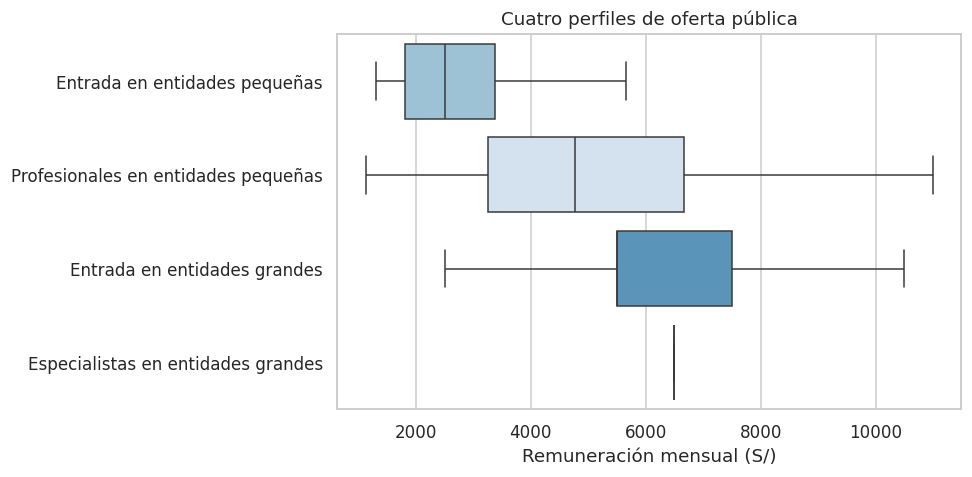

In [ ]:
NOMBRES = {
    0: "Profesionales en entidades pequeñas",
    1: "Entrada en entidades grandes",
    2: "Entrada en entidades pequeñas",
    3: "Especialistas en entidades grandes",
}
df["nombre_segmento"] = df["segmento"].map(NOMBRES)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df, x="remuneracion_pen", y="nombre_segmento",
            order=[NOMBRES[i] for i in perfil["remuneracion"].sort_values().index],
            hue="nombre_segmento", legend=False, palette="Blues", showfliers=False, ax=ax)
ax.set_xlabel("Remuneración mensual (S/)")
ax.set_ylabel("")
ax.set_title("Cuatro perfiles de oferta pública")
plt.tight_layout()
guardar_figura("05_segmentos_kmeans")
plt.show()

**Interpretación.** Los cuatro grupos se explican con dos rasgos: si el cargo es de entrada y si lo
publica una entidad grande o pequeña.

| Segmento | Ofertas | Mediana | Qué es |
|---|---|---|---|
| Entrada en entidades grandes | 233 | S/ 5.500 | Cargos de entrada en instituciones que publican cientos de convocatorias |
| Especialistas en entidades grandes | 194 | S/ 6.500 | Perfiles con trayectoria en esas mismas instituciones |
| Profesionales en entidades pequeñas | 385 | S/ 4.764 | Profesionales en entidades con pocas convocatorias |
| Entrada en entidades pequeñas | 194 | S/ 2.500 | Asistentes y auxiliares en entidades chicas |

El contraste entre los dos segmentos de entrada es el hallazgo central: **S/ 5.500 frente a S/ 2.500**. La
razón está en qué cargos abre cada bloque: las entidades grandes entran por analista o especialista de
primer nivel; las pequeñas, por asistente y auxiliar.

### 3.1 Perfil de los centroides

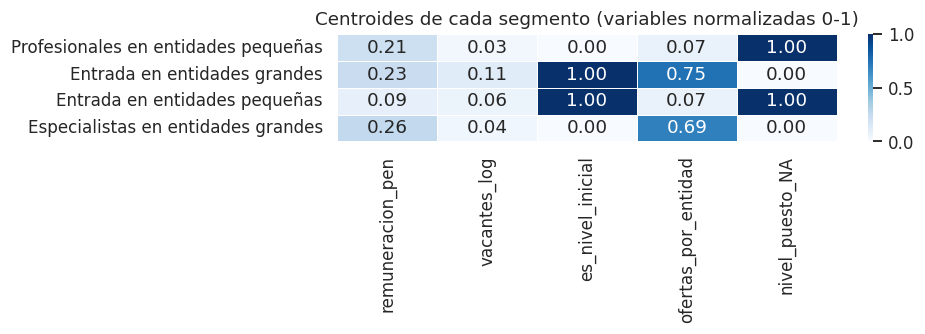

In [ ]:
# Centroides en la escala normalizada (0 a 1), como en el laboratorio de clustering
X_norm = pd.DataFrame(X, columns=VARIABLES)
centroides = pd.DataFrame(
    [X_norm[df["segmento"] == s].mean() for s in range(K)],
    index=[f"{NOMBRES[s]}" for s in range(K)],
)

plt.figure(figsize=(9, 3.2))
sns.heatmap(centroides, annot=True, fmt=".2f", cmap="Blues", linewidths=.5)
plt.title("Centroides de cada segmento (variables normalizadas 0-1)")
plt.tight_layout()
guardar_figura("05_centroides_segmentos")
plt.show()

**Interpretación.** `es_nivel_inicial` parte el dataset en dos y `ofertas_por_entidad` lo vuelve a
partir; `nivel_puesto_NA` acompaña esa división, porque las entidades grandes informan el nivel del cargo y
las pequeñas casi nunca. `vacantes_log` es parecida en los cuatro grupos: el número de vacantes no
distingue perfiles.

## 4. Anomalías

Se buscan las ofertas que se apartan del patrón en los tres niveles vistos en el laboratorio de outliers:
**univariado** (rango intercuartílico), **bivariado** (dos variables a la vez) y **multivariado**
(distancia de Mahalanobis). No se eliminan: la limpieza de la etapa 2 ya retiró los valores imposibles, de
modo que lo que queda son ofertas reales y lo que interesa es **qué las explica**.

### 4.1 Outliers univariados: remuneración

Límite superior: S/ 11,595 · ofertas por encima: 19 (1.9%)


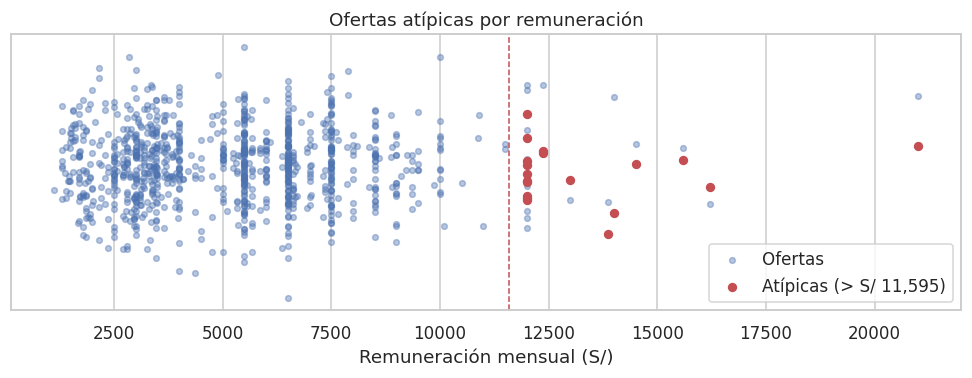

,puesto,entidad,tipo_entidad,remuneracion_pen
247,ASESOR DE MAGISTRADO,TRIBUNAL CONSTITUCIONAL,JUSTICIA Y MINISTERIO PUBLICO,21000.0
246,ASESOR JURISDICCIONAL II,TRIBUNAL CONSTITUCIONAL,JUSTICIA Y MINISTERIO PUBLICO,16200.0
343,COORDINADOR/A DE POLÍTICAS EN PLANEAMIENTO Y E...,MINISTERIO DE ENERGIA Y MINAS,GOBIERNO NACIONAL,15600.0
26,EJECUTIVO/A EN PRESUPUESTO POR RESULTADOS - EJ...,ORGANISMO DE EVALUACION Y FISCALIZACION AMBIEN...,GOBIERNO NACIONAL,14500.0
592,EXPERTO LEGAL EN GESTIÓN PÚBLICA,AUTORIDAD NACIONAL DE INFRAESTRUCTURA,GOBIERNO NACIONAL,14000.0


In [ ]:
q1, q3 = df["remuneracion_pen"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
atipicas = df[df["remuneracion_pen"] > limite]
print(f"Límite superior: S/ {limite:,.0f} · ofertas por encima: {len(atipicas)} ({len(atipicas) / len(df):.1%})")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.scatter(df["remuneracion_pen"], np.random.default_rng(42).normal(0, 0.06, len(df)),
           s=14, color=AZUL, alpha=0.4, label="Ofertas")
ax.scatter(atipicas["remuneracion_pen"], np.random.default_rng(7).normal(0, 0.06, len(atipicas)),
           s=26, color=ROJO, label=f"Atípicas (> S/ {limite:,.0f})")
ax.axvline(limite, color=ROJO, linestyle="--", linewidth=1)
ax.set_yticks([])
ax.set_xlabel("Remuneración mensual (S/)")
ax.set_title("Ofertas atípicas por remuneración")
ax.legend()
plt.tight_layout()
guardar_figura("05_anomalias_remuneracion")
plt.show()

atipicas[["puesto", "entidad", "tipo_entidad", "remuneracion_pen"]].nlargest(5, "remuneracion_pen")

In [ ]:
pd.DataFrame({
    "atípicas": atipicas["tipo_entidad"].value_counts(),
    "% del tipo": (atipicas["tipo_entidad"].value_counts()
                   / df["tipo_entidad"].value_counts() * 100).round(1),
}).dropna().sort_values("atípicas", ascending=False)

,atípicas,% del tipo
tipo_entidad,,
GOBIERNO NACIONAL,13.0,7.1
JUSTICIA Y MINISTERIO PUBLICO,6.0,6.8


**Interpretación.** Solo 19 ofertas (1,9 %) superan los S/ 11.595, y no son errores: son cargos de
asesoría y jefatura en organismos nacionales (13) y en el sistema de justicia (6), encabezados por un asesor
de magistrado del Tribunal Constitucional con S/ 21.000. Ningún gobierno local, universidad ni
establecimiento de salud aparece: el techo salarial está en el gobierno nacional y la justicia.

### 4.2 Outliers bivariados: remuneración y vacantes

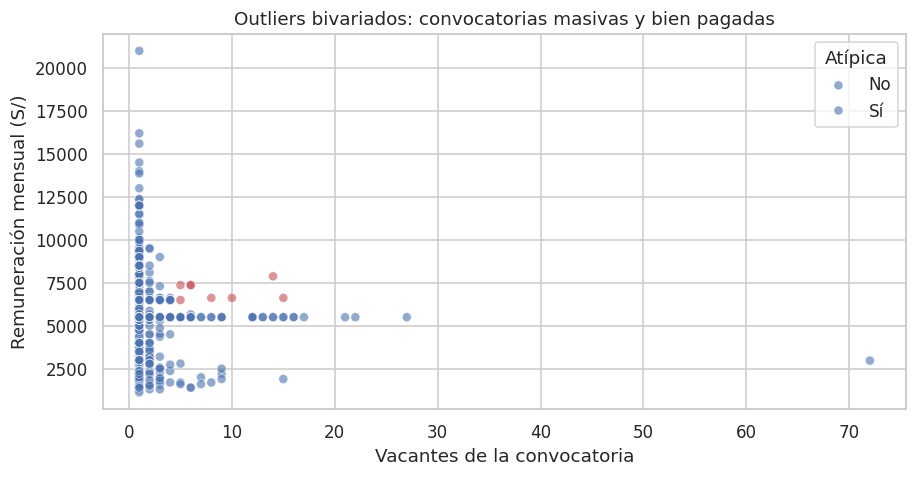

Ofertas atípicas en el plano remuneración-vacantes: 8


,puesto,entidad,vacantes,remuneracion_pen,masa_salarial_mensual
227,ESPECIALISTA JUDICIAL DE SALA,UNIDAD EJECUTORA 003 CORTE SUPERIOR DE JUSTICI...,14,7880.00,110320.00
231,ESPECIALISTA JUDICIAL DE AUDIENCIA,UNIDAD EJECUTORA 003 CORTE SUPERIOR DE JUSTICI...,15,6620.00,99300.00
229,ESPECIALISTA JUDICIAL DE JUZGADO,UNIDAD EJECUTORA 003 CORTE SUPERIOR DE JUSTICI...,10,6620.00,66200.00
234,ASISTENTE JURISDICCIONAL,UNIDAD EJECUTORA 003 CORTE SUPERIOR DE JUSTICI...,8,6620.00,52960.00
564,DEFENSOR PÚBLICO EN EL NUEVO CÓDIGO PROCESAL P...,MINISTERIO DE JUSTICIA Y DERECHOS HUMANOS,6,7364.19,44185.14
566,DEFENSOR PÚBLICO DE ASISTENCIA LEGAL SNEJ,MINISTERIO DE JUSTICIA Y DERECHOS HUMANOS,6,7364.19,44185.14
565,DEFENSOR PÚBLICO DE DEFENSA DE VÍCTIMAS SNEJ,MINISTERIO DE JUSTICIA Y DERECHOS HUMANOS,5,7364.19,36820.95
780,PERFIL 791-2026 ANALISTA II LEGAL EN EVALUACIÓ...,CONTRALORIA GENERAL DE LA REPUBLICA,5,6500.00,32500.00


In [ ]:
# Boolean mask construida a partir del gráfico, como en el laboratorio de outliers
BM = (df["remuneracion_pen"] > 6000) & (df["vacantes"] >= 5)
df["outlier_bivariado"] = BM

fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.scatterplot(data=df, x="vacantes", y="remuneracion_pen", hue="outlier_bivariado",
                palette={False: AZUL, True: ROJO}, alpha=0.6, s=35, ax=ax)
ax.set_xlabel("Vacantes de la convocatoria")
ax.set_ylabel("Remuneración mensual (S/)")
ax.set_title("Outliers bivariados: convocatorias masivas y bien pagadas")
ax.legend(title="Atípica", labels=["No", "Sí"])
plt.tight_layout()
guardar_figura("05_anomalias_bivariadas")
plt.show()

print(f"Ofertas atípicas en el plano remuneración-vacantes: {int(BM.sum())}")
df.loc[BM, ["puesto", "entidad", "vacantes", "remuneracion_pen", "masa_salarial_mensual"]]   .sort_values("masa_salarial_mensual", ascending=False)

**Interpretación.** La nube tiene forma de L: la mediana casi no cambia con el número de vacantes
(S/ 5.000 con una, S/ 5.500 con más), pero **el techo sí cae**: ninguna convocatoria de 10 o más vacantes
pasa de S/ 7.880, mientras que entre las de una sola plaza hay sueldos de S/ 21.000. Las ocho ofertas en
rojo rompen ese patrón y casi todas vienen del sistema de justicia; son las más valiosas para postular,
porque pagan por encima de la mediana y tienen varias plazas.

### 4.3 Outliers multivariados: distancia de Mahalanobis

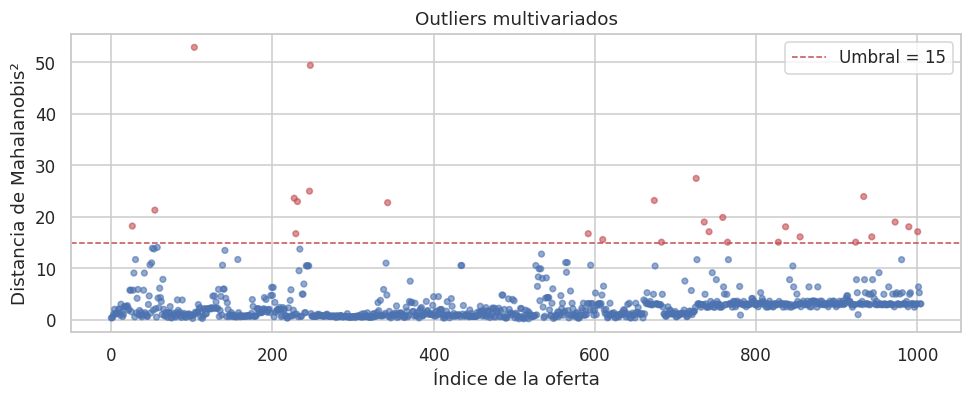

Ofertas con distancia mayor al umbral: 27 (2.7%)


,puesto,entidad,vacantes,remuneracion_pen,dist_maha
103,ESPECIALISTA JUDICIAL DE JUZGADO,PODER JUDICIAL,72,2972.0,52.9
247,ASESOR DE MAGISTRADO,TRIBUNAL CONSTITUCIONAL,1,21000.0,49.4
726,PERFIL 665-2026 AUDITOR/A ANALISTA I EN SISTEM...,CONTRALORIA GENERAL DE LA REPUBLICA,27,5500.0,27.5
246,ASESOR JURISDICCIONAL II,TRIBUNAL CONSTITUCIONAL,1,16200.0,25.0
934,PERFIL 592-2026 AUDITOR/A ANALISTA I EN SISTEM...,CONTRALORIA GENERAL DE LA REPUBLICA,22,5500.0,23.9
227,ESPECIALISTA JUDICIAL DE SALA,UNIDAD EJECUTORA 003 CORTE SUPERIOR DE JUSTICI...,14,7880.0,23.6
674,PERFIL 518-2026 AUDITOR/A ANALISTA I EN SISTEM...,CONTRALORIA GENERAL DE LA REPUBLICA,21,5500.0,23.2
231,ESPECIALISTA JUDICIAL DE AUDIENCIA,UNIDAD EJECUTORA 003 CORTE SUPERIOR DE JUSTICI...,15,6620.0,23.0


In [ ]:
from scipy.spatial.distance import mahalanobis

DIMENSIONES = ["remuneracion_pen", "vacantes_log", "ofertas_por_entidad"]
Xm = df[DIMENSIONES]
Xm = (Xm - Xm.min()) / (Xm.max() - Xm.min())   # normalización min-max

IC = np.linalg.pinv(Xm.cov().values)
media = Xm.mean().values
df["dist_maha"] = [mahalanobis(Xm.iloc[i, :], media, IC) ** 2 for i in range(len(Xm))]

UMBRAL = 15
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(df.index, df["dist_maha"], s=14,
           c=np.where(df["dist_maha"] > UMBRAL, ROJO, AZUL), alpha=0.6)
ax.axhline(UMBRAL, color=ROJO, linestyle="--", linewidth=1, label=f"Umbral = {UMBRAL}")
ax.set_xlabel("Índice de la oferta")
ax.set_ylabel("Distancia de Mahalanobis²")
ax.set_title("Outliers multivariados")
ax.legend()
plt.tight_layout()
guardar_figura("05_anomalias_mahalanobis")
plt.show()

extremas = df[df["dist_maha"] > UMBRAL]
print(f"Ofertas con distancia mayor al umbral: {len(extremas)} ({len(extremas) / len(df):.1%})")
extremas[["puesto", "entidad", "vacantes", "remuneracion_pen", "dist_maha"]]     .nlargest(8, "dist_maha").round(1)

**Interpretación.** La distancia de Mahalanobis mira las tres variables a la vez y su correlación, así
que detecta ofertas raras *en conjunto* aunque ningún valor lo sea por separado: aparecen casos que el
rango intercuartílico no marca, como convocatorias con muchas vacantes en entidades que casi no convocan.
No se eliminan, pero conviene tenerlas presentes porque son las que más pueden mover un promedio.

## 5. Insights y recomendaciones

Cada insight indica el hallazgo, la evidencia que lo respalda y qué puede hacer con él un estudiante o
recién egresado.

**Insight 1 · La puerta de entrada es más ancha de lo que parece, pero paga un tercio menos.**
*Evidencia:* 427 de 1.006 ofertas (42,4 %) son de nivel inicial, con una mediana de S/ 3.775 frente a
S/ 5.670 del resto (sección 1.2).
*Recomendación:* postular al sector público es viable sin experiencia previa; lo que conviene gestionar no
es el acceso sino la expectativa salarial de la primera posición.

**Insight 2 · El tamaño de la entidad define a qué cargo se entra, y con ello el sueldo.**
*Evidencia:* los segmentos de K-means separan la entrada en entidades grandes (S/ 5.500, con cargos de
analista o especialista de primer nivel) de la entrada en entidades pequeñas (S/ 2.500, con cargos de
asistente o auxiliar): más del doble de diferencia (sección 3).
*Recomendación:* priorizar convocatorias de entidades que publican muchas plazas —Contraloría, ministerios,
organismos nacionales, Poder Judicial— antes que filtrar solo por el nombre del puesto.

**Insight 3 · Las entidades que mejor pagan son también las que más puestos de entrada ofrecen.**
*Evidencia:* la Contraloría (S/ 6.500 de mediana, 56,8 % de ofertas iniciales) y el sistema de justicia
(S/ 5.670 y 53,4 %) lideran ambos indicadores, mientras que gobiernos locales y educación pagan S/ 2.500 y
S/ 2.817 (sección 2.2).
*Recomendación:* concentrar el esfuerzo de postulación en esas dos familias de entidades, que ofrecen la
mejor relación entre probabilidad de ingreso y remuneración.

**Insight 4 · Legal e ingeniería son las áreas con mejor relación entrada-sueldo; salud es la más engañosa.**
*Evidencia:* legal e ingeniería combinan ~41 % de ofertas de entrada con S/ 5.500 de mediana inicial; salud
pasa de S/ 4.364 de mediana general a S/ 2.797 en sus puestos de entrada (sección 2.1).
*Recomendación:* para quien estudia derecho o ingeniería, el sector público es una salida competitiva desde
el primer puesto; en salud conviene contar con que los cargos bien pagados exigen título y colegiatura.

**Insight 5 · El centralismo salarial es real y no lo explica una sola entidad.**
*Evidencia:* Lima-Callao concentra el 43,6 % de las ofertas y paga una mediana de S/ 6.500 frente a S/ 3.500
del resto del país (86 % más); al excluir a la Contraloría la brecha sigue en 78 % (S/ 6.000 frente a
S/ 3.374), sección 2.3.
*Recomendación:* al comparar ofertas de distintas regiones, hacerlo dentro de cada territorio y no en montos
absolutos; para quien no puede mudarse, el mejor objetivo son las sedes regionales de entidades nacionales,
que llevan la escala de pago de Lima al interior.

## 6. Conclusiones

1. **Sobre el objetivo general.** El dataset permite caracterizar la oferta pública vigente en el corte de
   septiembre de 2026 y, sobre todo, aislar el segmento accesible a estudiantes y recién egresados: 427
   ofertas de nivel inicial, el 42,4 % del total, con una mediana de S/ 3.775.

2. **Sobre qué determina el pago de entrada.** El factor con mayor efecto no es el área de estudios sino el
   tamaño de la entidad que convoca: la diferencia entre entrar por una institución grande o por una pequeña
   es de S/ 5.500 frente a S/ 2.500, y responde a que las entidades grandes abren su puerta de entrada en
   cargos profesionales mientras que las pequeñas lo hacen en puestos de asistente. Las variables
   construidas en la etapa 4 —`es_nivel_inicial`,
   `ofertas_por_entidad` y `tipo_entidad`— son las que hicieron visible ese patrón, que no se podía observar
   en los campos originales del portal.

3. **Sobre el territorio.** El centralismo se confirma tanto en volumen (43,6 % de las ofertas en
   Lima-Callao) como en remuneración (Lima paga 86 % más que el resto del país), y se mantiene al excluir la
   entidad que domina el dataset, donde la brecha sigue siendo del 78 %, de modo que no es un artefacto de
   la composición de la muestra.

4. **Limitaciones.** El análisis describe un corte de dos días y no una serie temporal, por lo que no
   permite afirmar nada sobre tendencias. Las variables `es_nivel_inicial`, `area_funcional` y
   `categoria_ocupacional` se infieren de la denominación del cargo, ya que el portal no publica experiencia
   ni formación exigida: son aproximaciones razonables, pero no datos declarados por la entidad. Además, una
   sola entidad concentra el 29,9 % de las ofertas, lo que obliga a verificar cada hallazgo con y sin ella,
   como se hizo en la sección 2.3. Por último, la fuente cubre solo el empleo público, así que las
   conclusiones no se extienden al mercado laboral peruano en su conjunto.

5. **Trabajo futuro.** Repetir la extracción de forma periódica convertiría la fotografía en una serie y
   permitiría estudiar estacionalidad y duración real de las convocatorias; incorporar las bases de cada
   convocatoria añadiría la experiencia y la formación exigidas, que es el dato que hoy debe estimarse.

## 7. Figuras guardadas para el informe

In [ ]:
figuras = sorted(p.name for p in DIR_FIGURAS.glob("05_*.png"))
print(f"{len(figuras)} figuras en reports/figures/:")
for f in figuras:
    print("  -", f)

12 figuras en reports/figures/:
  - 05_anomalias_bivariadas.png
  - 05_anomalias_mahalanobis.png
  - 05_anomalias_remuneracion.png
  - 05_areas_y_territorio.png
  - 05_centroides_segmentos.png
  - 05_composicion_salarial_macrorregion.png
  - 05_distribucion_remuneracion.png
  - 05_kmeans_seleccion_k.png
  - 05_nivel_inicial_vs_resto.png
  - 05_oportunidad_por_area.png
  - 05_remuneracion_por_tipo_entidad.png
  - 05_segmentos_kmeans.png


In [ ]:
!cd reports/figures && zip -q /content/figuras_05.zip 05_*.png
from google.colab import files
files.download("/content/figuras_05.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>